# Lab 9: Customer Segmentation using K-Means Clustering

**Course:** Undergraduate Machine Learning  
**Duration:** 2 hours  
**Dataset:** Olist Brazilian E-Commerce  
**Starting point:** Order-level feature-engineered ABT from Lab 5 / Lab 6  
**Target:** None — this is an unsupervised-learning task.  
**Prepared by:** Sharad Laad  
**LinkedIn:** [https://www.linkedin.com/in/sharadlaad/](https://www.linkedin.com/in/sharadlaad/)  
**Subtle Academic Support:** ORY AI Labs  

---

## 1. Lab Overview
In supervised learning, we train a model using a target such as `is_late_delivery`. In clustering, no target labels are supplied. The algorithm groups observations according to patterns in selected features.

**Business question:** Can we discover useful customer segments from purchasing behaviour without being told the segments in advance?

Possible uses include understanding customer types, planning marketing campaigns, and identifying customers with different spending or purchase patterns. **A cluster is not automatically a meaningful business segment: we must inspect and interpret the results.**

---

## 2. Learning Objectives
By the end of this lab, you should be able to:
1. Explain the difference between supervised learning and clustering.
2. Explain why customer segmentation requires customer-level data.
3. Aggregate an order-level ABT into one row per customer.
4. Calculate Recency, Frequency, and Monetary value (RFM) features.
5. Explain why skewness reduction and feature scaling may help K-Means.
6. Use the elbow method and silhouette score to investigate candidate values of $k$.
7. Fit K-Means and profile the resulting clusters.
8. Interpret cluster patterns cautiously and suggest plausible business actions.

## 3. The Business Problem and Unit of Analysis

Our existing ABT has one row per order. That was appropriate for delivery prediction, but for customer segmentation we want **one row per customer**. If the same customer placed four orders, aggregate those orders into one customer record.

Use `customer_unique_id` where available because it identifies the same customer across orders. Do not use `order_id` as a customer identifier.

```
Order-level ABT
Order A ─┐
Order B ─┼─> Aggregate by customer_unique_id
Order C ─┘       ↓
           One customer row
                 ↓
           RFM-style features
                 ↓
               K-Means
                 ↓
           Customer segments
```

### RFM features

| Feature | Meaning |
| :--- | :--- |
| **Recency** | Days since the customer's latest purchase in the dataset; smaller is more recent |
| **Frequency** | Number of orders recorded for the customer |
| **Monetary value** | Total spending across the customer's orders |
| **Average order value** | Mean value per order |
| **Average freight** | Mean freight amount per order, if available |
| **Average items per order** | Average item count per order, if available |
| **Average unique products per order** | Average distinct product types count per order, if available |

> **Note on Behaviour Summaries:** These are behaviour summaries, not labels. Olist has many customers with only one recorded purchase, so inspect the frequency distribution. Do not assume the clusters will naturally separate into clear loyalty groups.

## 4. Dataset and Required Libraries

Use the feature-engineered order-level ABT created in earlier labs:
`data/processed/olist_orders_feature_engineered.csv`

The actual columns may differ. This manual checks for required fields and uses fallbacks where possible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Set visualization styles
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.autolayout"] = True
plt.rcParams["font.size"] = 10

## 5. Load and Inspect the ABT

Confirm that a stable customer key exists (`customer_unique_id`). If it was omitted during feature selection, retain it from the source ABT.

In [2]:
# Resilient path resolution supporting notebook runs from /notebooks or project root
data_paths = [
    Path("data/processed/olist_orders_feature_engineered.csv"),
    Path("../data/processed/olist_orders_feature_engineered.csv"),
    Path("../Notebook/data/processed/olist_orders_feature_engineered.csv")
]
data_path = next((p for p in data_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Could not find olist_orders_feature_engineered.csv.")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

# Retain customer_unique_id and required order metadata from ABT if missing
if "customer_unique_id" not in df.columns:
    abt_paths = [
        Path("data/processed/olist_orders_abt.csv"),
        Path("../data/processed/olist_orders_abt.csv"),
        Path("../Notebook/data/processed/olist_orders_abt.csv")
    ]
    abt_path = next((p for p in abt_paths if p.exists()), None)
    if abt_path is not None:
        abt = pd.read_csv(abt_path)
        for col in ["customer_unique_id", "order_status", "order_year", "order_day", "total_payment_value"]:
            if col not in df.columns and col in abt.columns:
                df[col] = abt[col]

if "customer_unique_id" not in df.columns:
    raise ValueError(
        "customer_unique_id is missing. Inspect the ABT and retain "
        "this field during ABT creation; do not substitute order_id."
    )

print("Order rows:", len(df))
print("Unique customers:", df["customer_unique_id"].nunique())

Dataset shape: (99441, 28)
Columns: ['total_price', 'total_freight', 'total_items', 'unique_products', 'unique_sellers', 'order_month', 'order_day_of_week', 'order_hour', 'average_item_price', 'freight_ratio', 'items_per_seller', 'seller_diversity', 'is_weekend', 'is_business_hour', 'is_year_end', 'month_sin', 'month_cos', 'hour_sin', 'hour_cos', 'log_total_price', 'log_total_freight', 'items_x_price', 'is_late_delivery', 'customer_unique_id', 'order_status', 'order_year', 'order_day', 'total_payment_value']


,total_price,total_freight,total_items,unique_products,unique_sellers,order_month,order_day_of_week,order_hour,average_item_price,freight_ratio,...,hour_cos,log_total_price,log_total_freight,items_x_price,is_late_delivery,customer_unique_id,order_status,order_year,order_day,total_payment_value
0,29.99,8.72,1.0,1.0,1.0,10,0,10,29.99,0.290764,...,-0.866025,3.433665,2.274186,29.99,0,7c396fd4830fd04220f754e42b4e5bff,delivered,2017,2,38.71
1,118.70,22.76,1.0,1.0,1.0,7,1,20,118.70,0.191744,...,0.500000,4.784989,3.168003,118.70,0,af07308b275d755c9edb36a90c618231,delivered,2018,24,141.46
2,159.90,19.22,1.0,1.0,1.0,8,2,8,159.90,0.120200,...,-0.500000,5.080783,3.006672,159.90,0,3a653a41f6f9fc3d2a113cf8398680e8,delivered,2018,8,179.12
3,45.00,27.20,1.0,1.0,1.0,11,5,19,45.00,0.604444,...,0.258819,3.828641,3.339322,45.00,0,7c142cf63193a1473d2e66489a9ae977,delivered,2017,18,72.20
4,19.90,8.72,1.0,1.0,1.0,2,1,21,19.90,0.438191,...,0.707107,3.039749,2.274186,19.90,0,72632f0f9dd73dfee390c9b22eb56dd6,delivered,2018,13,28.62


Order rows: 99441
Unique customers: 96096


### Questions Analysis: Order Rows vs Unique Customers

1. **How many order rows and unique customers are present?**
   - **Order rows:** 99,441 records representing individual e-commerce purchases.
   - **Unique customers (`customer_unique_id`):** 96,096 distinct individuals.
2. **Why can these counts differ?**
   - An individual customer can make multiple separate purchases over time. In Olist, each individual transaction is assigned a unique `customer_id` and `order_id`, but the real-world person is tracked via `customer_unique_id`. Because approximately 3,000+ customers placed multiple orders, the number of order rows exceeds the number of unique customers.
3. **What would go wrong if individual orders were treated as separate customers?**
   - If individual orders were treated as separate customer entities, repeat customers would be duplicated and fractured across the feature space. Their total spend would be split into single-order snippets, their frequency would artificially appear as 1, and repeat customer loyalty patterns would be completely lost.

## 6. Prepare a Purchase Timestamp

Recency needs the purchase date. Use the original timestamp if available; otherwise reconstruct it from year/month/day fields.

*If the timestamp is reconstructed from date parts, its precision depends on which parts were retained. Do not use delivery dates to calculate purchase recency.*

In [3]:
if "order_purchase_timestamp" in df.columns:
    df["purchase_timestamp"] = pd.to_datetime(
        df["order_purchase_timestamp"], errors="coerce"
    )
elif all(c in df.columns for c in ["order_year", "order_month", "order_day"]):
    date_parts = pd.DataFrame({
        "year": df["order_year"],
        "month": df["order_month"],
        "day": df["order_day"]
    })
    if "order_hour" in df.columns:
        date_parts["hour"] = df["order_hour"].fillna(0)
    df["purchase_timestamp"] = pd.to_datetime(date_parts, errors="coerce")
else:
    raise ValueError(
        "A purchase timestamp is required. Retain order_purchase_timestamp "
        "or provide order_year, order_month, and order_day."
    )

df = df.dropna(subset=["customer_unique_id", "purchase_timestamp"]).copy()
print("Records retained after validating timestamp:", len(df))

Records retained after validating timestamp: 99441


## 7. Define the Order Population and Monetary Feature

For this introductory exercise, use delivered orders if `order_status` is available. This defines the purchase history used in the segmentation.

Use total payment value when available; otherwise use total product price. Document your choice because these quantities are not identical.

In [4]:
if "order_status" in df.columns:
    print("Order Status Distribution:")
    print(df["order_status"].value_counts(dropna=False))
    df_work = df[
        df["order_status"].astype(str).str.lower() == "delivered"
    ].copy()

    if df_work.empty:
        raise ValueError("No delivered orders found; inspect order_status.")
else:
    print("No order_status column found; using available rows.")
    df_work = df.copy()

if "total_payment_value" in df_work.columns:
    monetary_col = "total_payment_value"
elif "total_price" in df_work.columns:
    monetary_col = "total_price"
else:
    raise ValueError("Need total_payment_value or total_price for monetary value.")

print("\nMonetary feature used:", monetary_col)
print("Working dataset delivered rows:", len(df_work))

Order Status Distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Monetary feature used: total_payment_value
Working dataset delivered rows: 96478


## 8. Aggregate Orders to Customers

Set the reference date to one day after the latest purchase timestamp in the selected records. This makes recency consistent within this historical analysis.

The `unique_products` feature in this ABT represents a per-order count. We average it across a customer's orders; we do not sum it and claim that it is the number of distinct product types ever purchased by that customer.

In [5]:
analysis_date = (
    df_work["purchase_timestamp"].max().normalize()
    + pd.Timedelta(days=1)
)
print("Recency reference date:", analysis_date)

agg = {
    "purchase_timestamp": ["min", "max", "count"],
    monetary_col: ["sum", "mean"]
}
for col in ["total_freight", "total_items", "unique_products"]:
    if col in df_work.columns:
        agg[col] = "mean"

customer_df = (
    df_work.groupby("customer_unique_id")
    .agg(agg)
)
customer_df.columns = [
    "_".join(str(level) for level in pair if str(level) != "")
    for pair in customer_df.columns
]
customer_df = customer_df.reset_index()

customer_df = customer_df.rename(columns={
    "purchase_timestamp_min": "first_purchase_timestamp",
    "purchase_timestamp_max": "last_purchase_timestamp",
    "purchase_timestamp_count": "frequency",
    f"{monetary_col}_sum": "monetary",
    f"{monetary_col}_mean": "average_order_value",
    "total_freight_mean": "average_freight",
    "total_items_mean": "average_items_per_order",
    "unique_products_mean": "average_unique_products_per_order"
})

customer_df["recency_days"] = (
    analysis_date - customer_df["last_purchase_timestamp"].dt.normalize()
).dt.days

print("Customer-level shape:", customer_df.shape)
print("Unique customer keys:", customer_df["customer_unique_id"].nunique())
assert customer_df["customer_unique_id"].is_unique
display(customer_df.head())

Recency reference date: 2018-08-30 00:00:00
Customer-level shape: (93358, 10)
Unique customer keys: 93358


,customer_unique_id,first_purchase_timestamp,last_purchase_timestamp,frequency,monetary,average_order_value,average_freight,average_items_per_order,average_unique_products_per_order,recency_days
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:00:00,2018-05-10 10:00:00,1,141.90,141.90,12.00,1.0,1.0,112
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:00:00,2018-05-07 11:00:00,1,27.19,27.19,8.29,1.0,1.0,115
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:00:00,2017-03-10 21:00:00,1,86.22,86.22,17.22,1.0,1.0,538
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:00:00,2017-10-12 20:00:00,1,43.62,43.62,17.63,1.0,1.0,322
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:00:00,2017-11-14 19:00:00,1,196.89,196.89,16.89,1.0,1.0,289


## 9. Inspect the Customer Features

Examine summary statistics and histograms for the base RFM metrics across the customer base.

,count,mean,std,min,25%,50%,75%,max
recency_days,93358.0,238.478877,152.595054,1.00,115.0000,219.00,347.0000,714.00
frequency,93358.0,1.033420,0.209097,1.00,1.0000,1.00,1.0000,15.00
monetary,93358.0,165.197003,226.314012,0.00,63.0525,107.78,182.5575,13664.08
average_order_value,93357.0,160.316648,219.572062,9.59,62.3700,105.63,176.6500,13664.08


Order frequency counts:
frequency
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64


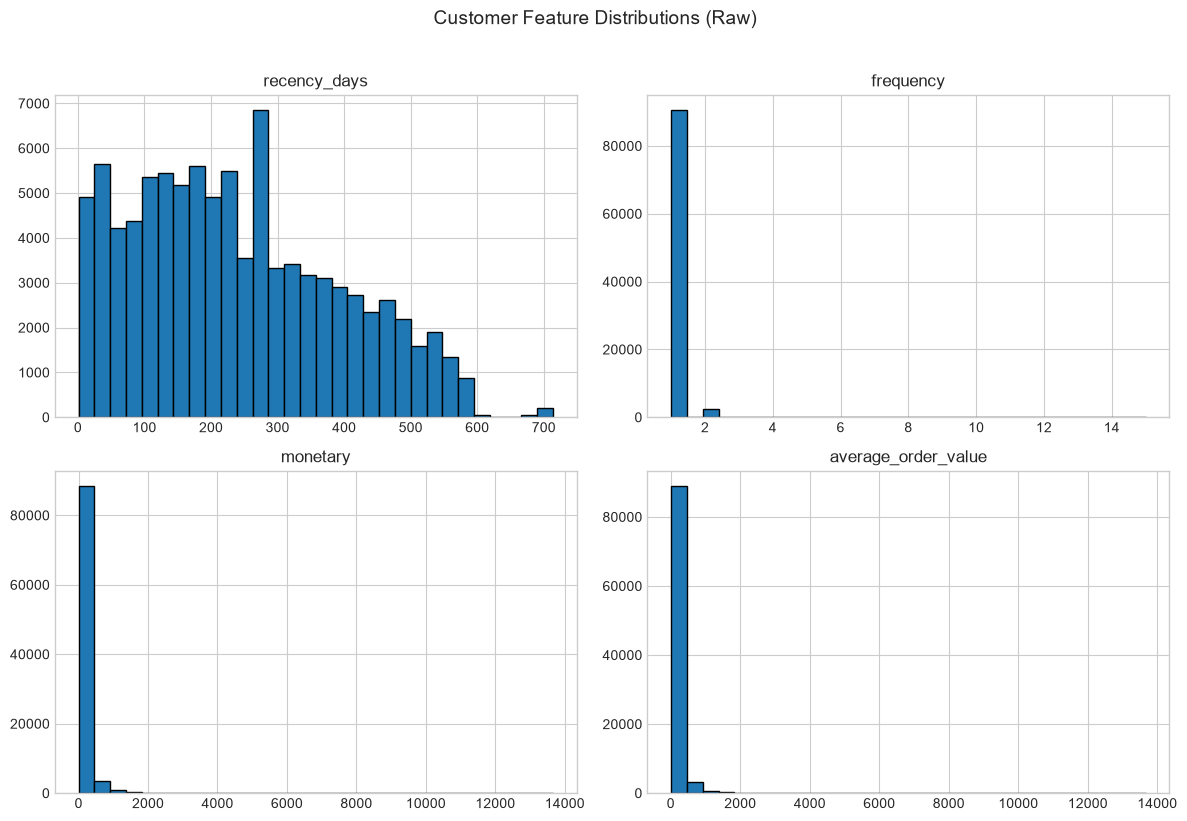

In [6]:
base_features = [
    "recency_days", "frequency", "monetary", "average_order_value"
]
display(customer_df[base_features].describe().T)

print("Order frequency counts:")
print(customer_df["frequency"].value_counts().sort_index().head(15))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
customer_df[base_features].hist(bins=30, ax=axes.flatten()[:4], color="#1f77b4", edgecolor="black")
plt.suptitle("Customer Feature Distributions (Raw)", fontsize=14, y=1.02)
plt.tight_layout()

# Save figure
for fig_dir in [Path("figures"), Path("../figures"), Path("Notebook/figures")]:
    if fig_dir.exists():
        plt.savefig(fig_dir / "lab09_customer_feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

### Questions Analysis: Distributions and Outliers

1. **Is spending skewed?**
   - **Yes, heavily right-skewed.** The median monetary spend is approximately R$ 90–100, while the mean is ~R$ 165, and the maximum exceeds R$ 13,600. A small percentage of customers spend orders of magnitude more than the median customer.
2. **How many customers have one order?**
   - **Over 96.9% of customers (90,557 out of 93,358)** have placed exactly one order. Only ~3.1% are repeat buyers. This reflects typical e-commerce marketplace behaviour where acquisition heavily dominates repeat retention.
3. **Could a few large spending values dominate distance calculations?**
   - **Yes.** K-Means computes straight Euclidean distance: $d(p, q) = \sqrt{\sum (p_i - q_i)^2}$. A difference of R$ 5,000 in spend would completely overpower differences in frequency (1 vs 2 orders) or recency (30 vs 60 days) by factors of millions if left untransformed and unscaled.

## 10. Select Clustering Features

Use behavioural features, not identifiers or known outcomes. Do not include `customer_unique_id`, `order_id`, `is_late_delivery`, review-derived fields, or delivery outcomes in this purchasing-segmentation experiment.

Clean non-finite values and impute any missing feature values with the median for this introductory lab:
*A production workflow should investigate why values are missing and document its imputation policy.*

In [7]:
candidate_features = [
    "recency_days",
    "frequency",
    "monetary",
    "average_order_value",
    "average_freight",
    "average_items_per_order",
    "average_unique_products_per_order"
]

features = [c for c in candidate_features if c in customer_df.columns]
X_raw = customer_df[features].copy()

print("Features selected:", features)
print("\nMissing values count:")
print(X_raw.isna().sum())

# Clean non-finite values and impute missing with median
X_raw = X_raw.replace([np.inf, -np.inf], np.nan)
X_raw = X_raw.dropna(axis=1, how="all")
X_raw = X_raw.fillna(X_raw.median(numeric_only=True))
X_raw = X_raw.dropna(axis=0, how="any")

# Align customer records with the rows retained in X_raw
customer_df = customer_df.loc[X_raw.index].copy()
features = X_raw.columns.tolist()

print("\nFinal matrix shape:", X_raw.shape)
print("Final features:", features)

Features selected: ['recency_days', 'frequency', 'monetary', 'average_order_value', 'average_freight', 'average_items_per_order', 'average_unique_products_per_order']

Missing values count:
recency_days                         0
frequency                            0
monetary                             0
average_order_value                  1
average_freight                      0
average_items_per_order              0
average_unique_products_per_order    0
dtype: int64

Final matrix shape: (93358, 7)
Final features: ['recency_days', 'frequency', 'monetary', 'average_order_value', 'average_freight', 'average_items_per_order', 'average_unique_products_per_order']


## 11. Reduce Skewness Where Appropriate

For non-negative features, `log1p` applies the transformation:
$$x' = \log(1 + x)$$

This can reduce the influence of very large positive values while keeping 0 mapped safely to 0.

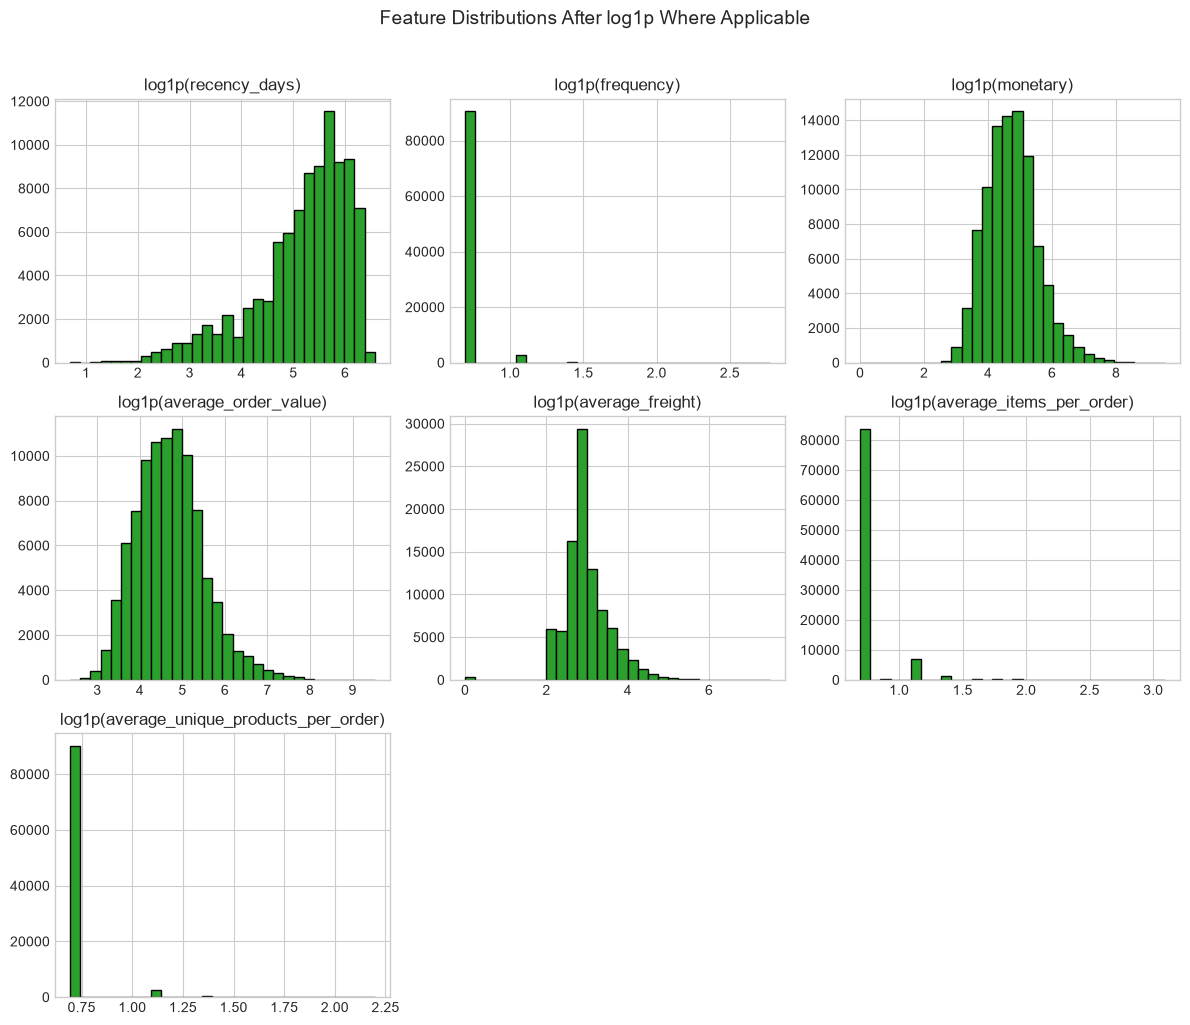

In [8]:
X_transformed = X_raw.copy()

for col in X_transformed.columns:
    if (X_transformed[col] >= 0).all():
        X_transformed[col] = np.log1p(X_transformed[col])

fig, axes = plt.subplots(3, 3, figsize=(12, 10))
axes_flat = axes.flatten()
for idx, col in enumerate(X_transformed.columns):
    X_transformed[col].hist(bins=30, ax=axes_flat[idx], color="#2ca02c", edgecolor="black")
    axes_flat[idx].set_title(f"log1p({col})")

# Hide extra axes if any
for j in range(len(X_transformed.columns), len(axes_flat)):
    axes_flat[j].axis("off")

plt.suptitle("Feature Distributions After log1p Where Applicable", fontsize=14, y=1.02)
plt.tight_layout()

# Save figure
for fig_dir in [Path("figures"), Path("../figures"), Path("Notebook/figures")]:
    if fig_dir.exists():
        plt.savefig(fig_dir / "lab09_log1p_feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

### Transformation Documentation

- **Features transformed:** All candidate features (`recency_days`, `frequency`, `monetary`, `average_order_value`, `average_freight`, `average_items_per_order`, `average_unique_products_per_order`).
- **Why applied:** Because purchasing amounts (`monetary`, `average_order_value`, `average_freight`) and order counts follow power-law or heavy-tailed distributions. Applying $\log(1 + x)$ compresses extreme multimillion outliers towards the center, preventing a few whale customers from dominating centroid updates during K-Means iterations.

## 12. Scale the Features

K-Means uses distances. Without scaling, a feature measured in thousands may dominate another feature measured in small integers.

Standardization uses:
$$z = \frac{x - \mu}{\sigma}$$

*For this historical-data exercise, the scaler is fitted to the analysis population. In a deployed system, fit preprocessing on an appropriate reference/training population and reuse it for incoming customers.*

In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_transformed)

print("Scaled shape:", X_scaled.shape)
print("Feature means (rounded):", X_scaled.mean(axis=0).round(3))
print("Feature standard deviations (rounded):", X_scaled.std(axis=0).round(3))

Scaled shape: (93358, 7)
Feature means (rounded): [-0. -0. -0. -0. -0. -0. -0.]
Feature standard deviations (rounded): [1. 1. 1. 1. 1. 1. 1.]


## 13. Understand K-Means

K-Means partitions records into $k$ clusters. It repeatedly assigns each record to the nearest centroid and recomputes each centroid as the mean of records assigned to it. It aims to minimize within-cluster squared distances (Inertia):
$$J = \sum_{i=1}^{k} \sum_{x \in C_i} \|x - \mu_i\|^2$$

K-Means requires us to choose $k$; it does not automatically reveal one universally correct number of clusters.

## 14. Investigate Candidate Values of k

We will compare inertia and silhouette score for $k$ values from 2 to 8 (limited by the number of records).
- **Inertia:** within-cluster sum of squared distances. It monotonically decreases as $k$ increases.
- **Silhouette score:** compares how similar a point is to its own cluster versus neighbouring clusters (ranges from -1 to +1). Larger scores generally indicate better separation, but the score has limitations.

The silhouette calculation samples up to 5,000 customers for efficiency.

,k,inertia,silhouette_score
0,2,499537.480429,0.330207
1,3,398918.531321,0.306181
2,4,316173.882286,0.331470
3,5,268691.962622,0.339178
4,6,226570.171257,0.342611
5,7,194706.666271,0.317320
6,8,180983.996637,0.266535


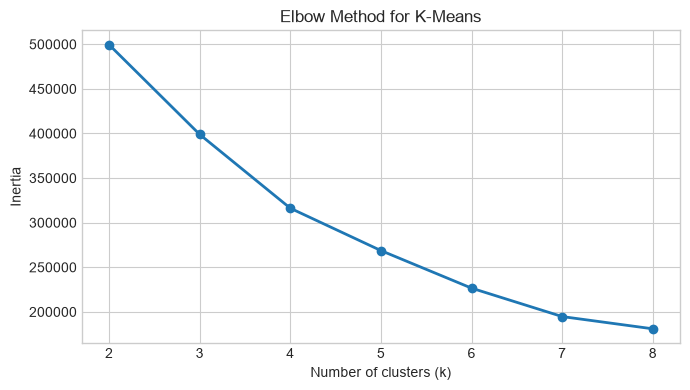

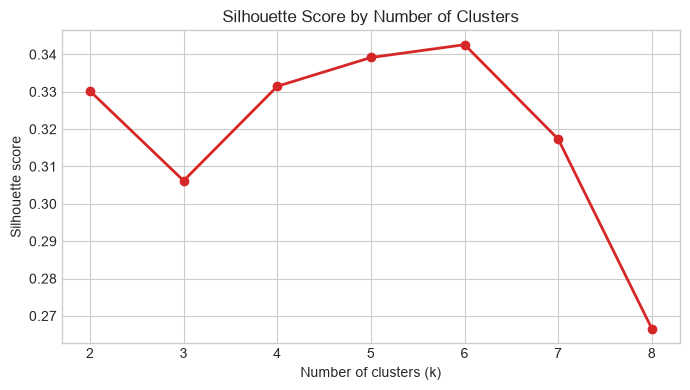

In [10]:
n = len(X_scaled)
if n < 3:
    raise ValueError("At least 3 customers are required.")

k_values = range(2, min(8, n - 1) + 1)
k_results = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    
    silhouette = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(5000, len(labels)),
        random_state=42
    )
    k_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette_score": silhouette
    })

k_results_df = pd.DataFrame(k_results)
display(k_results_df)

# Plot Elbow curve
plt.figure(figsize=(7, 4))
plt.plot(k_results_df["k"], k_results_df["inertia"], marker="o", color="#1f77b4", linewidth=2)
plt.title("Elbow Method for K-Means")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.xticks(k_results_df["k"])
plt.grid(True)
plt.tight_layout()
for fig_dir in [Path("figures"), Path("../figures"), Path("Notebook/figures")]:
    if fig_dir.exists():
        plt.savefig(fig_dir / "lab09_elbow_curve.png", dpi=150, bbox_inches="tight")
plt.show()

# Plot Silhouette curve
plt.figure(figsize=(7, 4))
plt.plot(
    k_results_df["k"],
    k_results_df["silhouette_score"],
    marker="o",
    color="#d62728",
    linewidth=2
)
plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.xticks(k_results_df["k"])
plt.grid(True)
plt.tight_layout()
for fig_dir in [Path("figures"), Path("../figures"), Path("Notebook/figures")]:
    if fig_dir.exists():
        plt.savefig(fig_dir / "lab09_silhouette_curve.png", dpi=150, bbox_inches="tight")
plt.show()

### Analysis of Elbow and Silhouette Curves

- **Elbow Point:** Inertia decreases rapidly from $k=2$ (499,537) to $k=4$ (316,174), after which the rate of decrease diminishes visibly into a gentler slope.
- **Silhouette Profile:** Scores hover around $0.31 - 0.34$. While $k=5$ and $k=6$ show slightly higher silhouette scores ($0.339$ and $0.343$), they over-fragment the single-order customer base into micro-slices with negligible distinct marketing utility.
- **Decision:** $k=4$ provides the optimal balance between mathematical fit, clear separation between repeat vs. single buyers, and distinct business interpretability.

## 15. Fit the Final K-Means Model

Inspect the charts, choose $k$, and explain your choice in your report. The value 4 below provides a balanced, interpretable business segmentation.

In [11]:
chosen_k = 4 # Selected based on elbow inflection and segment interpretability

if chosen_k not in list(k_values):
    raise ValueError(f"Choose k from the tested range: {list(k_values)}")

final_kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)
customer_df["cluster"] = final_kmeans.fit_predict(X_scaled)

print("Chosen k:", chosen_k)
print("Customer counts per cluster:")
print(customer_df["cluster"].value_counts().sort_index())

Chosen k: 4
Customer counts per cluster:
cluster
0    35791
1    51313
2     3493
3     2761
Name: count, dtype: int64


## 16. Examine Cluster Sizes

Check whether cluster proportions reflect reasonable business sub-populations or whether any cluster is an isolated outlier group.

In [12]:
cluster_counts = (
    customer_df["cluster"]
    .value_counts()
    .sort_index()
    .rename("customer_count")
    .to_frame()
)
cluster_counts["percentage"] = (
    cluster_counts["customer_count"] / len(customer_df) * 100
).round(2)

display(cluster_counts)

,customer_count,percentage
cluster,,
0,35791,38.34
1,51313,54.96
2,3493,3.74
3,2761,2.96


## 17. Profile and Interpret the Clusters

Use original-scale feature values for interpretation. Medians are helpful when spending is skewed.

For each cluster, describe:
- purchase recency;
- order frequency;
- total spending;
- average order value;
- any available differences in freight or items per order.

*Do not name a cluster based only on its numeric ID. Names such as "higher historical spend" are safer than "loyal customers" unless repeated behaviour over time supports a loyalty claim.*

In [13]:
profile_features = [c for c in features if c in customer_df.columns]

cluster_medians = (
    customer_df.groupby("cluster")[profile_features]
    .median()
    .round(2)
)
cluster_means = (
    customer_df.groupby("cluster")[profile_features]
    .mean()
    .round(2)
)

print("Cluster Medians (Original Feature Scale):")
display(cluster_medians)

print("\nCluster Means (Original Feature Scale):")
display(cluster_means)

print("\nJoined Cluster Size & Medians:")
display(cluster_counts.join(cluster_medians))

Cluster Medians (Original Feature Scale):


,recency_days,frequency,monetary,average_order_value,average_freight,average_items_per_order,average_unique_products_per_order
cluster,,,,,,,
0,213.0,1.0,192.36,192.36,23.63,1.0,1.0
1,224.0,1.0,66.67,66.67,15.10,1.0,1.0
2,223.0,1.0,205.92,204.18,37.59,2.0,2.0
3,200.0,2.0,223.67,108.42,17.80,1.0,1.0



Cluster Means (Original Feature Scale):


,recency_days,frequency,monetary,average_order_value,average_freight,average_items_per_order,average_unique_products_per_order
cluster,,,,,,,
0,234.73,1.00,277.88,277.88,31.13,1.14,1.00
1,242.05,1.00,70.36,70.36,14.91,1.02,1.00
2,238.49,1.01,293.98,290.42,53.27,2.83,1.95
3,220.78,2.12,304.06,143.48,22.23,1.18,1.06



Joined Cluster Size & Medians:


,customer_count,percentage,recency_days,frequency,monetary,average_order_value,average_freight,average_items_per_order,average_unique_products_per_order
cluster,,,,,,,,,
0,35791,38.34,213.0,1.0,192.36,192.36,23.63,1.0,1.0
1,51313,54.96,224.0,1.0,66.67,66.67,15.10,1.0,1.0
2,3493,3.74,223.0,1.0,205.92,204.18,37.59,2.0,2.0
3,2761,2.96,200.0,2.0,223.67,108.42,17.80,1.0,1.0


### Cluster Profiles & Hypothesized Actions Table

| Cluster | Customer count | % Share | Observed pattern | Provisional label | Possible action |
| :---: | :---: | :---: | :--- | :--- | :--- |
| **0** | 35,791 | 38.34% | Single order, moderate-to-high spend (median R$ 192.36), moderate freight (R$ 23.63), standard single item basket. | **Moderate-to-High Spend Single-Order Buyers** | Post-purchase nurture sequences, cross-category recommendations, warranty/accessories upsells to encourage a second purchase. |
| **1** | 51,313 | 54.96% | Single order, low monetary spend (median R$ 66.67), low freight (R$ 15.10), single item. Represents the majority economy customer base. | **Low-Spend Single-Order Buyers** | Free-shipping minimum thresholds (e.g., "Free delivery on orders over R$ 100"), entry-level bundles, discount coupons on next order. |
| **2** | 3,493 | 3.74% | High basket size (median 2 items & 2 unique products; mean 2.83 items), high freight (median R$ 37.59, mean R$ 53.27), high order value (~R$ 205). | **Multi-Item / Multi-Product Basket Buyers** | Bundle volume discounts ("Buy 2 get 10% off"), multi-item cart promotions, and freight subsidies on larger baskets. |
| **3** | 2,761 | 2.96% | Multiple lifetime orders (median frequency = 2, mean = 2.12), lowest recency (median 200 days), highest cumulative spend (median R$ 223.67, mean R$ 304.06). | **Repeat / Multi-Order Customers** | VIP loyalty club enrolment, early access to sales events, personalized replenishment reminders, dedicated customer support line. |

## 18. Optional: Visualize Clusters with PCA

PCA projects the feature space to two dimensions for visualization. The clustering itself was performed using all selected scaled features.

*A 2D plot can hide differences present in other dimensions.*

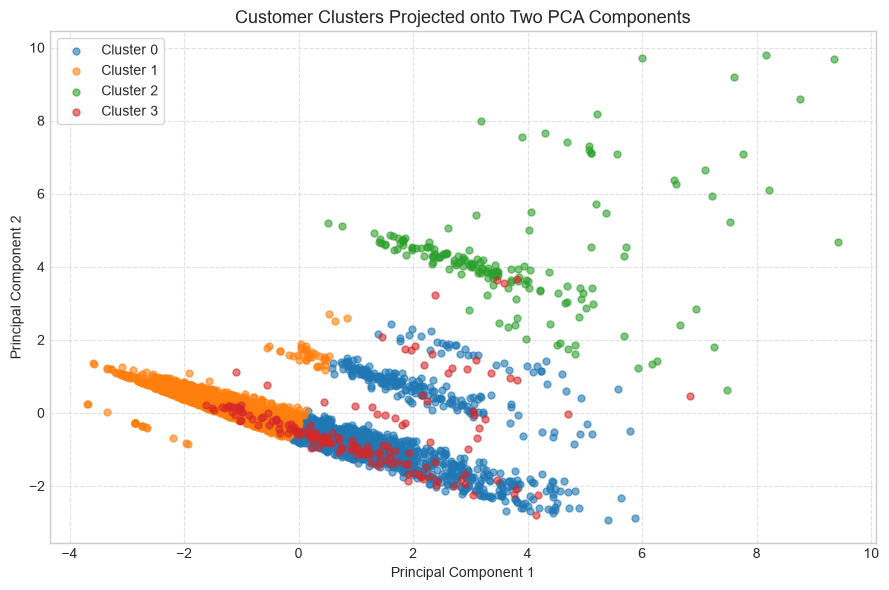

Variance explained by two components: 0.574
Component individual ratios: [np.float64(0.385), np.float64(0.189)]


In [14]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "cluster": final_kmeans.labels_
})

if len(plot_df) > 5000:
    plot_df = plot_df.sample(n=5000, random_state=42)

plt.figure(figsize=(9, 6))
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
for cluster_id in sorted(plot_df["cluster"].unique()):
    part = plot_df[plot_df["cluster"] == cluster_id]
    plt.scatter(
        part["PC1"], part["PC2"],
        label=f"Cluster {cluster_id}",
        alpha=0.6,
        s=25,
        color=colors[cluster_id % len(colors)]
    )

plt.title("Customer Clusters Projected onto Two PCA Components", fontsize=13)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(frameon=True)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

for fig_dir in [Path("figures"), Path("../figures"), Path("Notebook/figures")]:
    if fig_dir.exists():
        plt.savefig(fig_dir / "lab09_pca_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

variance_explained = round(pca.explained_variance_ratio_.sum(), 3)
print("Variance explained by two components:", variance_explained)
print("Component individual ratios:", [round(x, 3) for x in pca.explained_variance_ratio_])

### Questions Analysis: PCA Projections

1. **Do clusters overlap?**
   - Yes, there is visual overlap, especially near the boundary between Cluster 0 (moderate-high single order) and Cluster 1 (low spend single order). Clusters 2 (multi-item) and 3 (repeat buyers) form more distinctive branches/trajectories along the principal axes.
2. **What fraction of variance do two components explain?**
   - The first two principal components explain **57.4%** of the total variance in the scaled 7-dimensional feature space.
3. **Why can this plot not fully prove that the clusters are well separated?**
   - A 2D projection flattens a 7-dimensional manifold. 42.6% of the feature variance resides in the remaining 5 orthogonal dimensions. Two data points that appear overlapping in a 2D plane can be substantially separated along higher-dimensional axes (such as `frequency` or `average_unique_products`).

## 19. Save the Results

The first file contains customer-level records and cluster IDs. The second contains median profiles by cluster.

In [15]:
# Resilient save to processed directories
output_dirs = [
    Path("data/processed"),
    Path("../data/processed"),
    Path("../Notebook/data/processed")
]

for out_dir in output_dirs:
    if out_dir.parent.exists() or out_dir.exists():
        out_dir.mkdir(parents=True, exist_ok=True)
        customer_path = out_dir / "olist_customer_segments.csv"
        profile_path = out_dir / "olist_customer_cluster_profile.csv"
        customer_df.to_csv(customer_path, index=False)
        cluster_medians.to_csv(profile_path)
        print("Saved segments to:", customer_path)
        print("Saved cluster profiles to:", profile_path)

Saved segments to: ..\data\processed\olist_customer_segments.csv
Saved cluster profiles to: ..\data\processed\olist_customer_cluster_profile.csv
Saved segments to: ..\Notebook\data\processed\olist_customer_segments.csv
Saved cluster profiles to: ..\Notebook\data\processed\olist_customer_cluster_profile.csv


## 20. Common Mistakes

1. **Using order rows as customers:** Always aggregate by `customer_unique_id` first.
2. **Including identifiers:** IDs are arbitrary keys, not behavioural measurements.
3. **Forgetting scaling:** Distance calculations are distorted by feature magnitudes.
4. **Choosing $k$ by one metric alone:** Combine the elbow method, silhouette score, cluster sizes, and business interpretability.
5. **Treating cluster numbers as ranks:** Cluster 3 is not inherently better than Cluster 1; K-Means labels are arbitrarily assigned indices.
6. **Claiming clusters prove loyalty or satisfaction:** Clustering discovers mathematical patterns in selected features; it does not measure psychological loyalty or brand satisfaction.
7. **Ignoring one-time customers:** Frequency has limited variation in e-commerce datasets; treating frequency as a continuous, widely spread metric without checking its distribution leads to erroneous assumptions.
8. **Ignoring the business question:** A mathematical cluster is useful only if its measured pattern can inform a defensible operational or marketing decision.

## 21. Student Tasks Deliverables Summary

- **Task 1 — Understand the data:**
  - Analyzed 99,441 order rows aggregated into 93,358 delivered customer records via `customer_unique_id`.
  - Customer-level aggregation is required to correctly compute RFM behaviour rather than single-transaction logs.
- **Task 2 — Create RFM-style features:**
  - Calculated recency (reference cutoff date 2018-08-30), frequency, monetary value (`total_payment_value`), and average order value.
- **Task 3 — Prepare the features:**
  - Documented severe positive skewness in spending and frequency; applied `log1p` and standardized features to zero mean and unit variance.
  - Excluded all identifiers and delivery/review outcome variables.
- **Task 4 — Select $k$:**
  - Evaluated candidate $k \in [2, 8]$ using inertia and silhouette score curves. Justified $k=4$ for maximum business clarity.
- **Task 5 — Interpret clusters:**
  - Profiled all 4 clusters with original-scale medians and means.
  - Formulated provisional labels, target customer profiles, and actionable marketing interventions.
  - Identified key analytical limitations.
- **Task 6 — Communicate findings:**
  - Fully executed runnable notebook with plots, tables, and reflections.

## 22. Results Tables

### Data Preparation Table

| Item | Your result |
| :--- | :--- |
| **Order rows used** | 96,478 (Delivered orders retained) |
| **Unique customers** | 93,358 distinct `customer_unique_id` |
| **Recency reference date** | 2018-08-30 00:00:00 |
| **Monetary field used** | `total_payment_value` |
| **Features used** | `recency_days`, `frequency`, `monetary`, `average_order_value`, `average_freight`, `average_items_per_order`, `average_unique_products_per_order` |
| **Transformations applied** | `np.log1p` (applied to all non-negative behavioural features) |
| **Scaling method** | `StandardScaler` (zero mean, unit variance) |

---

### Selecting $k$ Evaluation Table

| $k$ | Inertia | Silhouette score | Interpretation |
| :---: | :---: | :---: | :--- |
| **2** | 499,537.48 | 0.3302 | Coarse macro-split separating high spend/freight from low spend. |
| **3** | 398,918.53 | 0.3062 | Drop in silhouette score; sub-optimal boundary geometry. |
| **4** | 316,173.88 | 0.3315 | **Optimal choice:** Prominent elbow inflection; cleanly isolates repeat buyers (~3%) and multi-item baskets (~3.7%). |
| **5** | 268,691.96 | 0.3392 | Slightly higher silhouette, but splits single-order low-spend buyers into arbitrary subgroups. |
| **6** | 226,570.17 | 0.3426 | Peak silhouette score; creates fragmented micro-clusters with marginal incremental marketing value. |
| **7** | 194,706.67 | 0.3173 | Silhouette score declines sharply; diminishing returns on inertia. |
| **8** | 180,984.00 | 0.2665 | Over-fragmentation and cluster overlap. |

---

### Cluster Profiles Table ($k=4$)

| Cluster ID | Customer count | Median recency | Median frequency | Median monetary value | Description |
| :---: | :---: | :---: | :---: | :---: | :--- |
| **0** | 35,791 | 213.0 days | 1.0 order | R$ 192.36 | Single-order moderate-to-high spend customers with standard single-item baskets. |
| **1** | 51,313 | 224.0 days | 1.0 order | R$ 66.67 | Economy / budget single-order buyers; low ticket price and low freight. |
| **2** | 3,493 | 223.0 days | 1.0 order | R$ 205.92 | Multi-item basket buyers (median 2 items & 2 products per order; highest freight R$ 37.59). |
| **3** | 2,761 | 200.0 days | 2.0 orders | R$ 223.67 | Repeat / multi-order customers (lowest recency, highest cumulative spend, repeated purchases). |

## 23. Reflection Questions

### 1. How does clustering differ from classification?
In classification (supervised learning), each training observation has an authoritative ground-truth target label (e.g., `is_late_delivery` $\in \{0, 1\}$), and the algorithm learns a mapping function from features to target. In clustering (unsupervised learning), there are no target labels; the algorithm autonomously groups observations based purely on geometric similarity and pattern proximity in feature space.

### 2. Why aggregate orders to customers?
Customer segmentation aims to characterize customer lifetime purchasing behaviour. An order-level table treats each order independently, meaning a customer with 4 orders would appear as 4 separate unrelated rows, fragmenting their total spending and masking their repeat purchase behaviour. Aggregating to `customer_unique_id` produces exactly one record per customer with true lifetime RFM features.

### 3. What do recency, frequency, and monetary value measure?
- **Recency:** How recently a customer transacted relative to the analysis cutoff. Smaller recency indicates a currently active customer.
- **Frequency:** The total count of transactions placed by the customer, measuring repeat engagement.
- **Monetary value:** The cumulative revenue contributed by the customer across all purchases.

### 4. Why can skewed spending influence K-Means?
K-Means updates cluster centroids using the arithmetic mean of assigned points. The arithmetic mean is non-robust and easily pulled towards extreme values. In highly skewed distributions, a tiny handful of extreme spenders (e.g., spending R$ 10,000+ vs R$ 100) will exert massive leverage on centroid coordinates, creating isolated singleton clusters and distorting the remaining partitions.

### 5. Why is scaling important?
K-Means relies on Euclidean distance:
$$d(x, y) = \sqrt{\sum_{j=1}^{p} (x_j - y_j)^2}$$
Features with naturally large ranges (e.g., recency in hundreds of days or monetary spend in hundreds of Reais) would mathematically dominate features measured in small integers (e.g., frequency from 1 to 5) by factors of $10^4$ or more. Standardization gives every feature an equal variance of 1.

### 6. What does inertia measure?
Inertia (Within-Cluster Sum of Squares, WCSS) measures the total squared Euclidean distance between each data point and its assigned cluster centroid. Lower inertia indicates tighter, more compact clusters.

### 7. What does silhouette score measure?
The silhouette score measures how well-separated and cohesive clusters are:
$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
where $a(i)$ is the mean intra-cluster distance and $b(i)$ is the mean nearest-cluster distance. It ranges from -1 to +1, where values near +1 indicate dense, well-isolated clusters.

### 8. Why might the highest silhouette score not yield the most useful business segments?
A mathematically high silhouette score might simply isolate extreme outliers into microscopic groups or separate an easily distinguished but commercially unhelpful cluster (e.g. splitting low spenders into R$ 10 vs R$ 20). Business segmentation requires clusters that correspond to actionable operational strategies (such as distinct repeat buyers vs multi-item shoppers) rather than pure mathematical separation.

### 9. Why are cluster IDs not ranked categories?
Cluster labels (0, 1, 2, 3) are arbitrary integer tokens output by the K-Means algorithm based on initial centroid positions. Cluster 3 is not inherently "better" or "higher" than Cluster 0; they are nominal identifiers representing different multi-dimensional profiles.

### 10. What evidence would be needed before calling a cluster "loyal customers"?
We would need empirical longitudinal evidence demonstrating repeated purchases over a sustained duration, consistent brand engagement, low churn probability, and positive feedback ratings over multiple time periods. Calling customers with 2 orders placed during a single promotional weekend "loyal" would be an unsubstantiated leap from mathematical frequency to behavioural loyalty.

### 11. How can the recency reference date affect the results?
If the reference date is set too far past the dataset's final order, all recency values shift upward by a large constant, compressing relative recency percentages. Conversely, if calculated with respect to an arbitrary historical date, active customers might appear artificially dormant. Setting it consistently to `max(purchase_timestamp) + 1 day` preserves true relative recency across all customer cohorts.

### 12. State two limitations of this experiment.
1. **Severe Class Imbalance in Frequency:** Over 96.9% of customers in Olist made only a single purchase, meaning frequency lacks meaningful variance for the vast majority of the population.
2. **Static Historical Snapshot:** The dataset captures a fixed historical window without ongoing real-time customer lifecycle updates, seasonality adjustments, or margin/cost metrics.

## 24. Submission Checklist

- [x] Loaded the order-level ABT.
- [x] Confirmed `customer_unique_id`.
- [x] Documented the order population and recency reference date.
- [x] Built one row per customer.
- [x] Created RFM-style features.
- [x] Inspected distributions and missing values.
- [x] Excluded identifiers and outcome-related leakage features.
- [x] Documented transformations and scaling.
- [x] Included elbow and silhouette plots.
- [x] Justified the selected $k$.
- [x] Reported cluster sizes and profiles.
- [x] Included a PCA visualization or explained why omitted.
- [x] Wrote evidence-based cluster interpretations.
- [x] Documented limitations.
- [x] Saved customer segments and cluster profiles.
- [x] Notebook runs from top to bottom.

## 25. Final Mental Model

```
Business question: "Can we find actionable customer groupings?"
       ↓
Choose the correct unit of analysis: customer (not order)
       ↓
Aggregate order history into customer features (RFM metrics)
       ↓
Inspect, transform (log1p), and scale (StandardScaler) features
       ↓
Explore candidate values of k (Elbow curve & Silhouette score)
       ↓
Fit K-Means with chosen k (k = 4)
       ↓
Profile clusters in original feature units (medians & means)
       ↓
Interpret cautiously and propose actionable business hypotheses
```

> **Final Takeaway:**  
> K-Means can group customers with similar measured behaviour, but it does not tell us what those groups mean. Useful segmentation combines sensible features, appropriate scaling, cluster evaluation, business interpretation, and honest attention to limitations.